# Membership Inference Attacks on a Fine-Tuned GPT-2

Reference-free membership inference against a GPT-2 model fine-tuned on WikiText-103 text. Three attacks, each needing only forward passes through the target model:

1. **Average loss**: members should have lower mean token loss.
2. **Min-K%**: average only the K% highest-loss tokens (Shi et al., 2024).
3. **zlib-normalized loss**: calibrate loss by compressed size (Carlini et al., 2021).

Evaluation: AUC, TPR at FPR < 1%, TPR at FPR < 5% on 2,000 texts (1,000 members, 1,000 non-members). See `README.md` for setup.

### Setup

In [ ]:
from pathlib import Path

project_root = Path.cwd().resolve()
print(f"Project root: {project_root}")

In [ ]:
import json
import os
import random
os.environ.setdefault("TRANSFORMERS_NO_TORCHVISION", "1")

import torch
import numpy as np
from datasets import Dataset
from torch.utils.data import DataLoader
from transformers import AutoTokenizer, AutoModelForCausalLM
from sklearn.metrics import roc_auc_score, roc_curve, auc as _auc
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)


In [ ]:
target_model_dir = project_root / "models" / "gpt2_target"
data_dir = project_root / "data"
batch_size = 25
block_size = 256  # max tokens per text; longer texts are truncated

### Data pre-processing

In [ ]:
def tokenize_dataset(ds, tok, max_len):
    ds = ds.filter(lambda ex: ex.get("text", None) and len(ex["text"].strip()) > 0)

    def _map(ex):
        out = tok(ex["text"], truncation=True, padding=True, max_length=max_len, return_attention_mask=True)
        out["labels"] = out["input_ids"].copy()
        return out

    ds = ds.map(_map, batched=True, remove_columns=ds.column_names)
    ds.set_format(type="torch", columns=["input_ids", "attention_mask", "labels"])
    return ds

def _read_json(path: Path):
    with path.open("r", encoding="utf-8") as f:
        return json.load(f)

In [ ]:
# load evaluation texts
data_dir = Path(data_dir)
test_path = data_dir / "test.json"
test_items = _read_json(test_path)
ds_test = Dataset.from_dict({"text": test_items})

# tokenize
tokenizer = AutoTokenizer.from_pretrained(target_model_dir, use_fast=True)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token
tokenizer.padding_side="right"

ds_test = tokenize_dataset(ds_test, tokenizer, block_size)
dl_test = DataLoader(ds_test, batch_size=batch_size)

if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")
print(f"Using device: {device}")

Using device: cuda


In [ ]:
model = AutoModelForCausalLM.from_pretrained(target_model_dir, dtype="auto").to(device)

### Walking through one batch

Next-token alignment: drop the last logit position and the first target/mask position, then take per-token cross-entropy and zero out padding.

In [ ]:
##inspecting one batch -> single batch attack
batch = next(iter(dl_test))
print(batch.keys())
input_ids = batch["input_ids"]
attention_mask = batch["attention_mask"]
print("Input IDs:", input_ids.shape)
print("Attention mask:", attention_mask.shape)

dict_keys(['input_ids', 'attention_mask', 'labels'])
Input IDs: torch.Size([25, 256])
Attention mask: torch.Size([25, 256])


In [ ]:
model.eval()
input_ids = input_ids.to(device)
attention_mask = attention_mask.to(device)
with torch.no_grad():
    outputs = model(
        input_ids=input_ids,
        attention_mask=attention_mask,
    )
logits = outputs.logits
print(logits.shape)

torch.Size([25, 256, 50257])


In [ ]:
shift_logits = logits[:, :-1, :] #to match each prediction with token it predicts
shift_targets = input_ids[:, 1:]
shift_mask = attention_mask[:, 1:]
print(shift_logits.shape)
print(shift_targets.shape)
print(shift_mask.shape)

torch.Size([25, 255, 50257])
torch.Size([25, 255])
torch.Size([25, 255])


In [ ]:
import torch.nn.functional as F
flat_logits = shift_logits.reshape(-1, shift_logits.shape[-1])
flat_targets = shift_targets.reshape(-1)
flat_losses = F.cross_entropy(
    flat_logits,
    flat_targets,
    reduction="none",
)
token_losses = flat_losses.reshape(shift_targets.shape)
print(token_losses.shape)

torch.Size([25, 255])


In [ ]:
##logprob loss
masked_losses = token_losses * shift_mask
total_loss = masked_losses.sum(dim=1)
valid_tokens = shift_mask.sum(dim=1)
assert (valid_tokens > 0).all(), "A text has no valid next-token targets"
mean_loss = total_loss / valid_tokens
batch_scores = -mean_loss

print(batch_scores.shape)
print(batch_scores[:5])

torch.Size([25])
tensor([-2.1429, -3.2187, -3.0214, -2.6799, -2.8912], device='cuda:0')


In [ ]:
##min-k
valid_losses = token_losses[0][shift_mask[0].bool()]
k_percent = 20
n_select = max(1, int(valid_losses.numel() * k_percent / 100))
hardest_losses = torch.topk(
    valid_losses, k=n_select, largest=True
).values
min_k_score = -hardest_losses.mean()

print("Tokens selected:", n_select, "of", valid_losses.numel())
print("Loss score:", -valid_losses.mean().item())
print("Min-K score:", min_k_score.item())

Tokens selected: 40 of 200
Loss score: -2.1429355144500732
Min-K score: -5.846963882446289


### Attack 1: average loss

In [ ]:
@torch.no_grad()
def loss_attack(model,dataloader,device):
  model.eval()
  scores=[]

  for batch in dataloader:
    input_ids = batch["input_ids"].to(device)
    attention_mask = batch["attention_mask"].to(device)
    outputs = model(
        input_ids=input_ids,
        attention_mask=attention_mask,
    )
    logits = outputs.logits
    shift_logits = logits[:, :-1, :] #to match each prediction with token it predicts
    shift_targets = input_ids[:, 1:]
    shift_mask = attention_mask[:, 1:]
    flat_logits = shift_logits.reshape(-1, shift_logits.shape[-1])
    flat_targets = shift_targets.reshape(-1)
    flat_losses = F.cross_entropy(
        flat_logits,
        flat_targets,
        reduction="none",
    )
    token_losses = flat_losses.reshape(shift_targets.shape)
    masked_losses = token_losses * shift_mask
    total_loss = masked_losses.sum(dim=1)
    valid_tokens = shift_mask.sum(dim=1)
    assert (valid_tokens > 0).all(), "A text has no valid next-token targets"
    mean_loss = total_loss / valid_tokens
    batch_scores = -mean_loss
    scores.extend(batch_scores.cpu().tolist())
  return scores

scores_test = loss_attack(model, dl_test, device)
print(len(scores_test))

2000


### Attack 2: Min-K%

In [ ]:
@torch.no_grad()
def min_k_attack(model,dataloader,device,k_percent):
  model.eval()
  scores=[]

  for batch in dataloader:
    input_ids = batch["input_ids"].to(device)
    attention_mask = batch["attention_mask"].to(device)
    outputs = model(
        input_ids=input_ids,
        attention_mask=attention_mask,
    )
    logits = outputs.logits
    shift_logits = logits[:, :-1, :] #to match each prediction with token it predicts
    shift_targets = input_ids[:, 1:]
    shift_mask = attention_mask[:, 1:]
    flat_logits = shift_logits.reshape(-1, shift_logits.shape[-1])
    flat_targets = shift_targets.reshape(-1)
    flat_losses = F.cross_entropy(
        flat_logits,
        flat_targets,
        reduction="none",
    )
    token_losses = flat_losses.reshape(shift_targets.shape)
    for losses, mask in zip(token_losses, shift_mask):
      valid_losses = losses[mask.bool()]
      assert valid_losses.numel() > 0, "No valid target tokens."

      n_select = max(1, int(valid_losses.numel() * k_percent / 100))

      hardest_losses = torch.topk(
          valid_losses, k=n_select, largest=True
      ).values

      min_k_score = -hardest_losses.mean()
      scores.append(min_k_score.item())
  return scores

min_k_scores = min_k_attack(model, dl_test, device, k_percent=20)
print(len(min_k_scores))

2000


Cache per-token losses once, so different K values can be evaluated without re-running the model.

In [ ]:
@torch.no_grad()
def collect_token_losses(model, dataloader, device):
  model.eval()
  all_losses = []

  for batch in dataloader:
    input_ids = batch["input_ids"].to(device)
    attention_mask = batch["attention_mask"].to(device)
    outputs = model(
        input_ids=input_ids,
        attention_mask=attention_mask,
    )
    logits = outputs.logits
    shift_logits = logits[:, :-1, :] #to match each prediction with token it predicts
    shift_targets = input_ids[:, 1:]
    shift_mask = attention_mask[:, 1:]
    flat_logits = shift_logits.reshape(-1, shift_logits.shape[-1])
    flat_targets = shift_targets.reshape(-1)
    flat_losses = F.cross_entropy(
        flat_logits,
        flat_targets,
        reduction="none",
    )
    token_losses = flat_losses.reshape(shift_targets.shape)
    for losses, mask in zip(token_losses, shift_mask):
      valid_losses = losses[mask.bool()]
      assert valid_losses.numel() > 0, "No valid target tokens."
      all_losses.append(valid_losses.cpu().numpy())

  return all_losses

cached_losses = collect_token_losses(model, dl_test, device)
print(len(cached_losses))

2000


### Evaluation

In [ ]:
# membership labels (1 = member), used only for evaluation
label_path = data_dir / "test_label.json"
label_items = _read_json(label_path)

y_true = np.array(label_items)
scores = np.array(scores_test)
fpr, tpr, thr = roc_curve(y_true, scores)
auc_val = roc_auc_score(y_true, scores)
print(auc_val) # area under curve

# some tpr fpr
print(max(tpr[fpr < 0.01])) # TPR @ 0.01FPR
print(max(tpr[fpr < 0.05])) # TPR @ 0.05FPR

0.713577
0.033
0.195


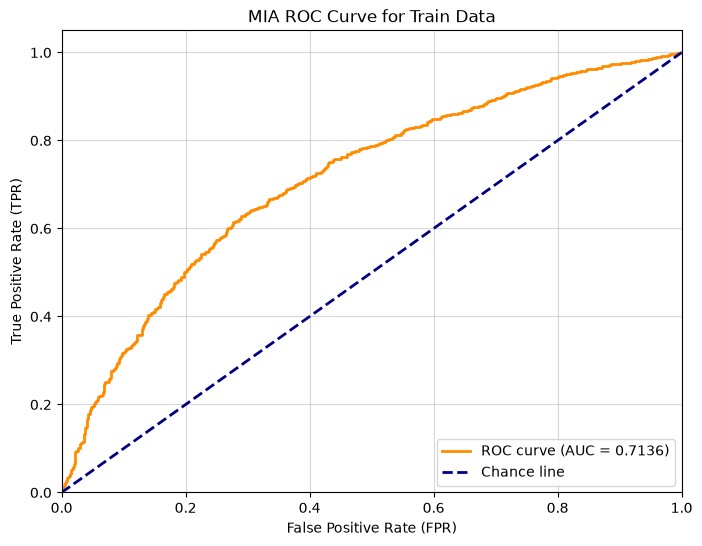

In [ ]:
# ROC curve for the average-loss attack
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {auc_val:.4f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Chance line')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate (TPR)')
plt.title(f'Average-loss attack ROC')
plt.legend(loc="lower right")
plt.grid(alpha=0.5)
plt.show()

In [ ]:
loss_scores = np.array(scores_test).copy()

In [ ]:
# Min-K% (K = 20%)
min_k_scores = np.array(min_k_scores)
fpr_k, tpr_k, _ = roc_curve(y_true, min_k_scores)

In [ ]:
auc_k = roc_auc_score(y_true, min_k_scores)
tpr_1_k = max(tpr_k[fpr_k < 0.01])
tpr_5_k = max(tpr_k[fpr_k < 0.05])

print("AUC:", auc_k)
print("TPR below 1% FPR:", tpr_1_k)
print("TPR below 5% FPR:", tpr_5_k)

AUC: 0.708503
TPR below 1% FPR: 0.045
TPR below 5% FPR: 0.181


Sanity check: Min-K% at K = 100% must equal the average-loss attack.

In [ ]:
min_k_100_scores = min_k_attack(
    model, dl_test, device, k_percent=100
)
print(np.allclose(min_k_100_scores, loss_scores, atol=1e-5))

True


Sweep over K using the cached token losses.

In [ ]:
percentages = [5, 10, 20, 40, 60, 80, 100]
scores_by_k = {}
for k in percentages:
  scores = []

  for losses in cached_losses:
    n_select = max(1, int(len(losses) * k / 100))
    hardest_losses = np.sort(losses)[-n_select:]
    scores.append(-hardest_losses.mean())
    scores_by_k[k] = np.array(scores)

  fpr_k, tpr_k, _ = roc_curve(y_true, scores_by_k[k])
  auc_k = roc_auc_score(y_true, scores_by_k[k])
  tpr_1 = max(tpr_k[fpr_k < 0.01])
  tpr_5 = max(tpr_k[fpr_k < 0.05])

  print(f"K={k:3d}% | AUC={auc_k:.4f} | TPR@1%={tpr_1:.3f} | TPR@5%={tpr_5:.3f}")

K=  5% | AUC=0.7050 | TPR@1%=0.054 | TPR@5%=0.170
K= 10% | AUC=0.7088 | TPR@1%=0.059 | TPR@5%=0.167
K= 20% | AUC=0.7085 | TPR@1%=0.045 | TPR@5%=0.181
K= 40% | AUC=0.7108 | TPR@1%=0.032 | TPR@5%=0.191
K= 60% | AUC=0.7153 | TPR@1%=0.030 | TPR@5%=0.189
K= 80% | AUC=0.7143 | TPR@1%=0.036 | TPR@5%=0.196
K=100% | AUC=0.7136 | TPR@1%=0.033 | TPR@5%=0.195


### Attack 3: zlib-normalized loss

Compressed size is measured on the decoded model input (after truncation), so it matches exactly the text the loss was computed on.

In [ ]:
# single-example walkthrough
import zlib

text = test_items[0]
text_bytes = text.encode("utf-8")
compressed_bytes = zlib.compress(text_bytes)
print("Original bytes:", len(text_bytes))
print("Compressed bytes:", len(compressed_bytes))

full_ids = tokenizer(text, truncation=False)["input_ids"]
print("Full token count:", len(full_ids))
print("Token limit:", block_size)

used_ids = full_ids[:block_size]
used_text = tokenizer.decode(
    used_ids,
    clean_up_tokenization_spaces=False,
)
used_zlib_size = len(zlib.compress(used_text.encode("utf-8")))
print("Compressed bytes for model input:", used_zlib_size)

Original bytes: 983
Compressed bytes: 446
Full token count: 201
Token limit: 256
Compressed bytes for model input: 446


In [ ]:
zlib_sizes = []

for example in ds_test:
    valid_ids = example["input_ids"][example["attention_mask"].bool()]
    used_text = tokenizer.decode(
        valid_ids.tolist(),
        clean_up_tokenization_spaces=False,
    )
    compressed_size = len(zlib.compress(used_text.encode("utf-8")))
    zlib_sizes.append(compressed_size)
zlib_scores = loss_scores / np.array(zlib_sizes)

fpr_z, tpr_z, _ = roc_curve(y_true, zlib_scores)

print("AUC:", roc_auc_score(y_true, zlib_scores))
print("TPR below 1% FPR:", max(tpr_z[fpr_z < 0.01]))
print("TPR below 5% FPR:", max(tpr_z[fpr_z < 0.05]))

AUC: 0.5929409999999999
TPR below 1% FPR: 0.054
TPR below 5% FPR: 0.142


### Comparison

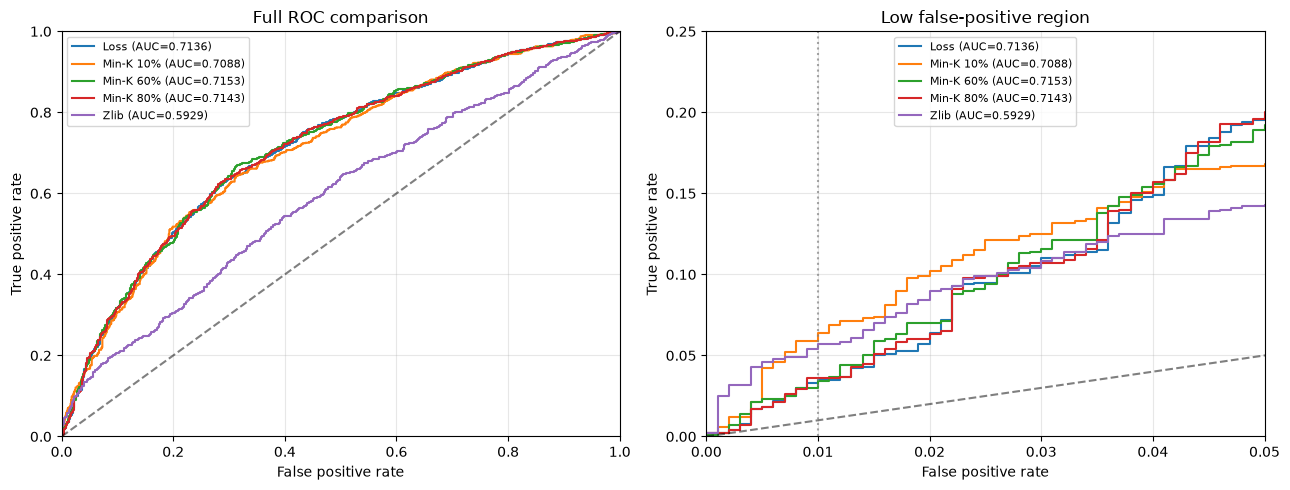

In [ ]:
attack_scores = {
    "Loss": loss_scores,
    "Min-K 10%": scores_by_k[10],
    "Min-K 60%": scores_by_k[60],
    "Min-K 80%": scores_by_k[80],
    "Zlib": zlib_scores,
}
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for name, scores in attack_scores.items():
    fpr, tpr, _ = roc_curve(y_true, scores)
    auc_value = roc_auc_score(y_true, scores)

    for ax in axes:
        ax.plot(fpr, tpr, label=f"{name} (AUC={auc_value:.4f})")

for ax in axes:
  ax.plot([0, 1], [0, 1], "k--", alpha=0.5)
  ax.set_xlabel("False positive rate")
  ax.set_ylabel("True positive rate")
  ax.grid(alpha=0.3)
  ax.legend(fontsize=8)
axes[0].set_title("Full ROC comparison")
axes[0].set_xlim(0, 1)
axes[0].set_ylim(0, 1)

axes[1].set_title("Low false-positive region")
axes[1].set_xlim(0, 0.05)
axes[1].set_ylim(0, 0.25)
axes[1].axvline(0.01, color="gray", linestyle=":", alpha=0.7)

plt.tight_layout()
plt.show()